# Import

In [3]:
import os, re, cv2, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, log_loss, classification_report

# Connexion to Drive

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
DATA_DIR = "/content/drive/MyDrive/ML- pipeline_Formative-2/images-files"
OUTPUT_DIR = "/content/drive/MyDrive/ML- pipeline_Formative-2/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for member in sorted(os.listdir(DATA_DIR)):
    print(member, sorted(os.listdir(f"{DATA_DIR}/{member}")))

Janviere  ['Neutral.jpg', 'Smiling.jpg', 'Surprised.jpg']
Josue ['Josue-Neutral.jpg', 'Josue-Smiling.jpg', 'Josue-Surprised.jpg']
Thomas ['Neutral.jpg', 'Smiling .jpg', 'Surprised .jpg']
Yohan ['Neutral.jpg', 'Smiling .jpg', 'Surprised .jpg']


# Load image and detect expression

In [6]:
def get_expression(filename):
    n = filename.lower()
    if "neutral" in n or "neutre" in n: return "neutral"
    if "smil" in n or "sourir" in n:    return "smiling"
    if "surpr" in n:                    return "surprised"
    return "unknown"

images = []  # (member, expression, image)
for member in sorted(os.listdir(DATA_DIR)):
    for file in sorted(os.listdir(f"{DATA_DIR}/{member}")):
        img = cv2.imread(f"{DATA_DIR}/{member}/{file}")
        if img is None:
            continue
        img = cv2.resize(img, (128, 128))
        images.append((member, get_expression(file), img))

print(len(images), "images loaded")
print([(m, e) for m, e, _ in images])

12 images loaded
[('Janviere ', 'neutral'), ('Janviere ', 'smiling'), ('Janviere ', 'surprised'), ('Josue', 'neutral'), ('Josue', 'smiling'), ('Josue', 'surprised'), ('Thomas', 'neutral'), ('Thomas', 'smiling'), ('Thomas', 'surprised'), ('Yohan', 'neutral'), ('Yohan', 'smiling'), ('Yohan', 'surprised')]


# Display Sample Picture of each member

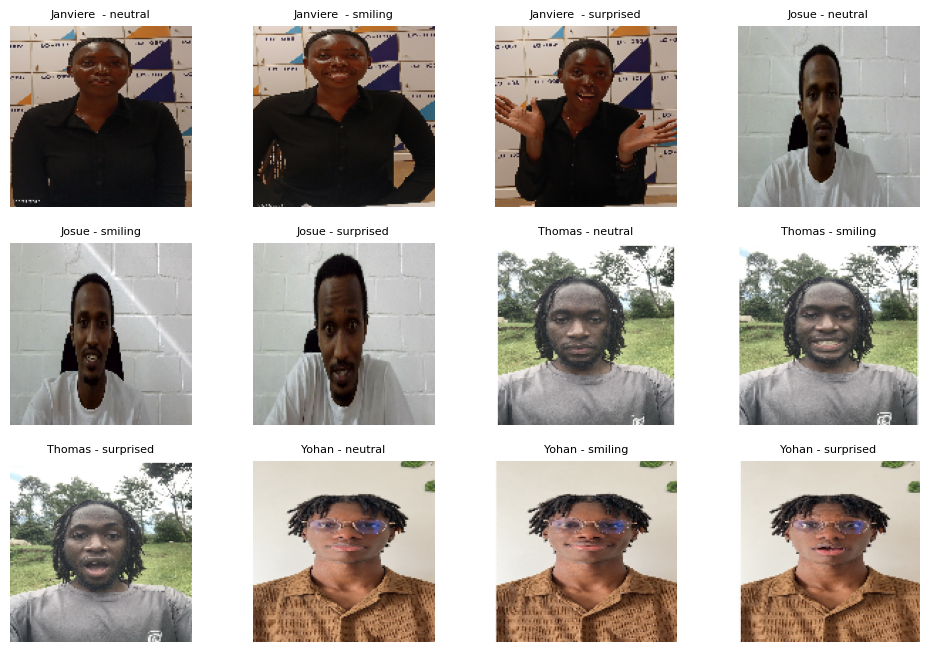

In [7]:
plt.figure(figsize=(12, 8))
for i, (member, expr, img) in enumerate(images):
    plt.subplot(3, 4, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{member} - {expr}", fontsize=8)
    plt.axis("off")
plt.show()

# Image Augmentation

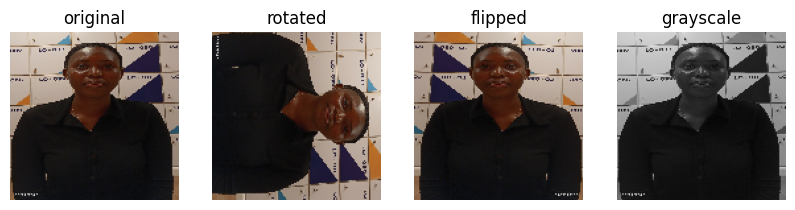

In [8]:
def augmentations(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return {
        "original": img,
        "rotated": cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE),
        "flipped": cv2.flip(img, 1),
        "grayscale": cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR),
    }

# Display one example
augs = augmentations(images[0][2])
plt.figure(figsize=(10, 3))
for i, (name, im) in enumerate(augs.items()):
    plt.subplot(1, 4, i + 1)
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    plt.title(name)
    plt.axis("off")
plt.show()

# Feature extraction and saving image_features.csv

In [9]:
def get_features(img, bins=32):
    feats = []
    for ch in range(3):  # blue, green, red
        h = cv2.calcHist([img], [ch], None, [bins], [0, 256]).flatten()
        feats.extend(h / h.sum())
    return feats

rows = []
for member, expr, img in images:
    for aug_name, aug_img in augmentations(img).items():
        row = {"member": member, "expression": expr, "augmentation": aug_name}
        for i, v in enumerate(get_features(aug_img)):
            row[f"feat_{i}"] = v
        rows.append(row)

df = pd.DataFrame(rows)
df.to_csv(f"{OUTPUT_DIR}/image_features.csv", index=False)
print(df.shape)

(48, 99)


# Train/Test split

In [10]:
feat_cols = [c for c in df.columns if c.startswith("feat_")]

train = df[df["expression"] != "surprised"]
test = df[df["expression"] == "surprised"]

X_train, y_train = train[feat_cols], train["member"]
X_test, y_test = test[feat_cols], test["member"]
print(len(train), "train rows,", len(test), "test rows")

32 train rows, 16 test rows


# Train and evaluate

In [11]:
model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)

print("Accuracy :", accuracy_score(y_test, pred))
print("F1-score :", f1_score(y_test, pred, average="macro"))
print("Loss     :", log_loss(y_test, proba, labels=model.classes_))

Accuracy : 1.0
F1-score : 1.0
Loss     : 0.3776467597692168


# Save Model for the demo

In [12]:
joblib.dump(model, f"{OUTPUT_DIR}/face_model.pkl")
print("Model saved")

Model saved
